# Coursework 1 - Market Analysis and Stock Segmentation Using RFM

In [31]:
# Setup, Configuration & Package Versions
# %pip install -q yfinance lxml html5lib beautifulsoup4 scikit-learn scipy matplotlib pandas numpy

import io
import json
import platform
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy
import sklearn
import yfinance as yf
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------- Configuration ----------------
START = "2021-01-01"          # inclusive
END = "2025-01-01"            # exclusive in yfinance -> last session 2024-12-31
BENCH = "^GSPC"
BASELINE = 20                 # preceding trading sessions for rolling volume mean
WINDOW = 60                   # latest trading sessions for Frequency & Monetary
MULT = 2.0                    # high-volume threshold multiplier (strictly > 2x)
SEED = 42
K_RANGE = range(2, 9)         # feasible k from 2 to 8
USE_CACHE = True              # True: reuse saved snapshots if available; False: fresh live pull
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

OUT = Path("outputs")
FIG = OUT / "figures"
CACHE = OUT / "cache"
for d in (OUT, FIG, CACHE):
    d.mkdir(parents=True, exist_ok=True)

versions = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "matplotlib": plt.matplotlib.__version__,
}
(OUT / "package_versions.txt").write_text("\n".join(f"{k}=={v}" for k, v in versions.items()))
print("Download library used: yfinance")
for k, v in versions.items():
    print(f"  {k:13s}: {v}")


Download library used: yfinance
  python       : 3.13.18
  platform     : Linux-6.6.159+-x86_64-with-glibc2.39
  pandas       : 2.2.3
  numpy        : 2.4.6
  yfinance     : 0.2.66
  scikit-learn : 1.6.1
  scipy        : 1.16.3
  matplotlib   : 3.10.0


## Task 1 Data Preparation and Feature Engineering

### 1.1 Ticker selection and data acquisition


In [32]:
excl_log = []
def log_event(ticker, stage, rule, detail, action="EXCLUDE"):
    excl_log.append({
        "Ticker": ticker, "Stage": stage, "Rule": rule, "Detail": detail, "Action": action
    })

# Locate existing local snapshot if USE_CACHE is True (works both locally and in Colab)
EXISTING_CHUNK1 = Path("../01_chunk1_prices")
CONS_CACHE = CACHE / "sp500_constituents.csv"
RAW_CACHE = CACHE / "prices_raw_2021-01-01_to_2024-12-31.csv"
SPLITS_CACHE = CACHE / "splits_events.csv"
DATE_CACHE = CACHE / "retrieval_date.txt"

if USE_CACHE and not CONS_CACHE.exists() and (EXISTING_CHUNK1 / "sp500_constituents.csv").exists():
    cons_src = EXISTING_CHUNK1 / "sp500_constituents.csv"
    raw_src = EXISTING_CHUNK1 / "prices_raw_2021-01-01_to_2024-12-31.csv"
    splits_src = EXISTING_CHUNK1 / "splits_events.csv"
    date_src = EXISTING_CHUNK1 / "retrieval_date.txt"
    cons = pd.read_csv(cons_src, keep_default_na=False)
    RETRIEVAL_DATE = date_src.read_text().strip()
    data_mode = "local cached snapshot (01_chunk1_prices)"
    cons.to_csv(CONS_CACHE, index=False)
    DATE_CACHE.write_text(RETRIEVAL_DATE)
    raw_long = pd.read_csv(raw_src, parse_dates=["Date"], dtype={"Ticker": str})
    splits_df = pd.read_csv(splits_src, parse_dates=["Date"], dtype={"Ticker": str}) if splits_src.exists() else pd.DataFrame(columns=["Date", "Ticker", "Split"])
elif USE_CACHE and CONS_CACHE.exists() and RAW_CACHE.exists():
    cons = pd.read_csv(CONS_CACHE, keep_default_na=False)
    RETRIEVAL_DATE = DATE_CACHE.read_text().strip()
    data_mode = "outputs/cache snapshot"
    raw_long = pd.read_csv(RAW_CACHE, parse_dates=["Date"], dtype={"Ticker": str})
    splits_df = pd.read_csv(SPLITS_CACHE, parse_dates=["Date"], dtype={"Ticker": str}) if SPLITS_CACHE.exists() else pd.DataFrame(columns=["Date", "Ticker", "Split"])
else:
    resp = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (university coursework)"}, timeout=30)
    resp.raise_for_status()
    cons = pd.read_html(io.StringIO(resp.text), match="Symbol")[0]
    RETRIEVAL_DATE = datetime.now(timezone.utc).strftime("%Y-%m-%d")
    cons.to_csv(CONS_CACHE, index=False)
    DATE_CACHE.write_text(RETRIEVAL_DATE)
    data_mode = "live Wikipedia + yfinance"

    cons["YahooTicker"] = cons["Symbol"].astype(str).str.replace(".", "-", regex=False)
    all_syms = cons["YahooTicker"].drop_duplicates().tolist() + [BENCH]
    parts, sp_parts = [], []
    for i in range(0, len(all_syms), 50):
        batch = all_syms[i:i + 50]
        d = yf.download(batch, start=START, end=END, auto_adjust=False, actions=True,
                        group_by="ticker", progress=False, threads=True)
        if not isinstance(d.columns, pd.MultiIndex):
            d.columns = pd.MultiIndex.from_product([[batch[0]], d.columns])
        top = set(d.columns.get_level_values(0))
        for t in batch:
            if t not in top:
                continue
            sub = d[t].reindex(columns=["Open", "High", "Low", "Close", "Adj Close", "Volume"]).dropna(how="all")
            if sub.empty:
                continue
            sub = sub.reset_index().rename(columns={"index": "Date"})
            sub["Date"] = pd.to_datetime(sub["Date"]).dt.tz_localize(None)
            sub.insert(1, "Ticker", t)
            parts.append(sub)
            if "Stock Splits" in d[t].columns:
                sp = d[t]["Stock Splits"]
                sp = sp[sp.fillna(0) > 0].rename("Split").reset_index().rename(columns={"index": "Date"})
                sp["Date"] = pd.to_datetime(sp["Date"]).dt.tz_localize(None)
                sp.insert(1, "Ticker", t)
                sp_parts.append(sp)
    raw_long = pd.concat(parts, ignore_index=True)
    splits_df = pd.concat(sp_parts, ignore_index=True) if sp_parts else pd.DataFrame(columns=["Date", "Ticker", "Split"])
    raw_long.to_csv(RAW_CACHE, index=False)
    splits_df.to_csv(SPLITS_CACHE, index=False)

cons["YahooTicker"] = cons["Symbol"].astype(str).str.replace(".", "-", regex=False)
changed = cons[cons["YahooTicker"] != cons["Symbol"]]
for _, r in changed.iterrows():
    log_event(r["YahooTicker"], "1.1 Acquisition", "ticker_format", f"{r['Symbol']} -> {r['YahooTicker']}", "INFO")

tickers = cons["YahooTicker"].drop_duplicates().tolist()
sector_map = cons.drop_duplicates("YahooTicker").set_index("YahooTicker")["GICS Sector"]
security_map = cons.drop_duplicates("YahooTicker").set_index("YahooTicker")["Security"]
date_added_map = cons.drop_duplicates("YahooTicker").set_index("YahooTicker")["Date added"]

# Pivot to wide DataFrames (Dates x Tickers)
raw_long["Date"] = pd.to_datetime(raw_long["Date"]).dt.tz_localize(None)
adj_all = raw_long.pivot_table(index="Date", columns="Ticker", values="Adj Close", aggfunc="first").sort_index()
close_all = raw_long.pivot_table(index="Date", columns="Ticker", values="Close", aggfunc="first").sort_index()
vol_all = raw_long.pivot_table(index="Date", columns="Ticker", values="Volume", aggfunc="first").sort_index()

bench_adj = adj_all[BENCH].dropna()
bench_dates = bench_adj.index

print(f"Data source          : {data_mode}")
print(f"Retrieval date       : {RETRIEVAL_DATE}")
print(f"Requested S&P shares : {len(tickers)} (plus 1 benchmark {BENCH} = {len(tickers) + 1} series total)")
print(f"Ticker renames (.-)  : {dict(zip(changed['Symbol'], changed['YahooTicker']))}")
print(f"Benchmark ({BENCH})   : {len(bench_dates)} trading sessions ({bench_dates.min().date()} to {bench_dates.max().date()})")


Data source          : outputs/cache snapshot
Retrieval date       : 2026-11-24
Requested S&P shares : 503 (plus 1 benchmark ^GSPC = 504 series total)
Ticker renames (.-)  : {'BRK.B': 'BRK-B', 'BF.B': 'BF-B'}
Benchmark (^GSPC)   : 1005 trading sessions (2021-01-04 to 2024-12-31)


### 1.2 Data validation and alignment


In [33]:
# Duplicate date check in raw long table
dup_pairs = int(raw_long.duplicated(subset=["Date", "Ticker"]).sum())
print(f"Duplicate (Date, Ticker) rows in raw data: {dup_pairs}")
assert dup_pairs == 0, "Unexpected duplicate (Date, Ticker) rows!"

# Reindex share matrices strictly onto benchmark trading calendar (no silent filling!)
adj_shares = adj_all.reindex(index=bench_dates, columns=tickers)
close_shares = close_all.reindex(index=bench_dates, columns=tickers)
vol_shares = vol_all.reindex(index=bench_dates, columns=tickers)

valid_tickers = []
for t in tickers:
    if adj_shares[t].isna().all():
        log_event(t, "1.2 Validation", "no_data", "No rows returned in 2021-01-01 to 2024-12-31 (post-period listing/rebrand)")
        continue

    miss_adj = int(adj_shares[t].isna().sum())
    miss_close = int(close_shares[t].isna().sum())
    miss_vol = int(vol_shares[t].isna().sum())
    if miss_adj + miss_close + miss_vol > 0:
        first_dt = adj_shares[t].first_valid_index().date()
        log_event(t, "1.2 Validation", "unequal_history",
                  f"Missing {miss_adj} AdjClose / {miss_close} Close / {miss_vol} Volume sessions (first valid {first_dt})")
        continue

    if (adj_shares[t] <= 0).any() or (close_shares[t] <= 0).any():
        log_event(t, "1.2 Validation", "nonpositive_price", "Non-positive Close or Adj Close detected")
        continue

    bad_vol = int((vol_shares[t] <= 0).sum())
    if bad_vol > 0:
        log_event(t, "1.2 Validation", "volume_error", f"{bad_vol} session(s) with zero or negative volume")
        continue

    valid_tickers.append(t)

# Corporate-action check on retained shares: Close/Adj Close ratio jumps > 10%
adj_v = adj_shares[valid_tickers].copy()
close_v = close_shares[valid_tickers].copy()
vol_v = vol_shares[valid_tickers].copy()

ratio = close_v / adj_v
ratio_jump = ratio.pct_change(fill_method=None).abs()
big_jumps = ratio_jump.stack()
big_jumps = big_jumps[big_jumps > 0.10]
print(f"Corporate-action ratio jumps >10% among retained shares: {len(big_jumps)} (splits recorded in snapshot: {len(splits_df)})")

excl_df = pd.DataFrame(excl_log)
excl_only = excl_df[excl_df["Action"] == "EXCLUDE"].reset_index(drop=True)
excl_df.to_csv(OUT / "exclusion_log.csv", index=False)

# Hard assertions on validated dataset
assert adj_v.isna().sum().sum() == 0
assert close_v.isna().sum().sum() == 0
assert vol_v.isna().sum().sum() == 0
assert (adj_v > 0).all().all() and (close_v > 0).all().all() and (vol_v > 0).all().all()

print(f"\nRequested shares : {len(tickers)}")
print(f"Excluded shares  : {len(excl_only)}")
print(f"Retained shares  : {len(valid_tickers)} (all with {len(bench_dates)} aligned sessions, 0 NaNs)")
print("\nExclusion summary by rule:")
print(excl_only["Rule"].value_counts().to_string())
print("\nExcluded tickers:")
print(excl_only[["Ticker", "Rule", "Detail"]].to_string(index=False))


Duplicate (Date, Ticker) rows in raw data: 0
Corporate-action ratio jumps >10% among retained shares: 0 (splits recorded in snapshot: 61)

Requested shares : 503
Excluded shares  : 17
Retained shares  : 486 (all with 1005 aligned sessions, 0 NaNs)

Exclusion summary by rule:
Rule
unequal_history    10
no_data             5
volume_error        2

Excluded tickers:
Ticker            Rule                                                                          Detail
   APP unequal_history    Missing 70 AdjClose / 70 Close / 70 Volume sessions (first valid 2021-04-15)
  COIN unequal_history    Missing 69 AdjClose / 69 Close / 69 Volume sessions (first valid 2021-04-14)
   CEG unequal_history Missing 263 AdjClose / 263 Close / 263 Volume sessions (first valid 2022-01-19)
   EXE unequal_history    Missing 26 AdjClose / 26 Close / 26 Volume sessions (first valid 2021-02-10)
  FDXF         no_data      No rows returned in 2021-01-01 to 2024-12-31 (post-period listing/rebrand)
  FERG    volume

### 1.3 Weekly return and weekly beta

In [34]:
def to_complete_weekly_returns(price_df):
    w = price_df.resample("W-FRI").last()
    week_monday = w.index - pd.Timedelta(days=4)
    # Keep only weeks whose Mon-Fri span lies completely inside [START, END-1day]
    keep = (week_monday >= pd.Timestamp(START)) & (w.index <= pd.Timestamp(END) - pd.Timedelta(days=1))
    w = w.loc[keep]
    return w.pct_change(fill_method=None).iloc[1:]

weekly_ret = to_complete_weekly_returns(adj_v)
bench_weekly_ret = to_complete_weekly_returns(bench_adj.to_frame(BENCH))[BENCH]

# Align strictly on identical week labels
common_weeks = weekly_ret.index.intersection(bench_weekly_ret.index)
weekly_ret = weekly_ret.loc[common_weeks]
bench_weekly_ret = bench_weekly_ret.loc[common_weeks]

assert weekly_ret.isna().sum().sum() == 0
assert bench_weekly_ret.isna().sum() == 0

bench_var = bench_weekly_ret.var(ddof=1)
mean_weekly_ret = weekly_ret.mean()
weekly_beta = weekly_ret.apply(lambda s: s.cov(bench_weekly_ret) / bench_var)

df_risk = pd.DataFrame({
    "Mean_Weekly_Return": mean_weekly_ret,
    "Weekly_Beta": weekly_beta,
    "Paired_Weeks": len(common_weeks),
})

print(f"Weekly return window : {common_weeks.min().date()} to {common_weeks.max().date()} ({len(common_weeks)} weeks)")
print(f"Shares with valid return & beta: {len(df_risk)} (all with {int(df_risk['Paired_Weeks'].min())} paired weeks)")
print(df_risk[["Mean_Weekly_Return", "Weekly_Beta"]].describe().round(5))


Weekly return window : 2021-01-15 to 2024-12-27 (207 weeks)
Shares with valid return & beta: 486 (all with 207 paired weeks)
       Mean_Weekly_Return  Weekly_Beta
count           486.00000    486.00000
mean              0.00286      0.97370
std               0.00265      0.40734
min              -0.00447      0.05545
25%               0.00118      0.66660
50%               0.00262      0.95061
75%               0.00421      1.17954
max               0.01777      3.77856


### 1.4 & 1.5 - Adapted RFM Calculations, Metric interpretation and supporting evidence (`AAPL`)


Unit tests passed (Recency=5/0/NaN, strict >2x threshold, Close*Volume=$200M).
Observation date : 2024-12-31 | 60-session window: 2024-10-07 to 2024-12-31
Shares with no qualifying event (R=NaN): 0
Shares with F=0 in latest 60 sessions  : 10
Shares with R=0 (event on obs date)    : 0

=== Worked Example: AAPL (Observation date: 2024-12-31) ===
Qualifying high-volume days in latest 60 sessions (2):
                 Close       Volume  Prev20_Mean_Vol  Threshold_2x  Traded_Value_USD
Date                                                                                
2024-11-25  232.869995   90152800.0       43820740.0    87641480.0      2.099388e+10
2024-12-20  254.490005  147495300.0       45004605.0    90009210.0      3.753608e+10
R = (2024-12-31 - 2024-12-20) = 11 calendar days
F = 2 qualifying days in latest 60 sessions
M = $623,303,377,706.58 ($623.30 billion)


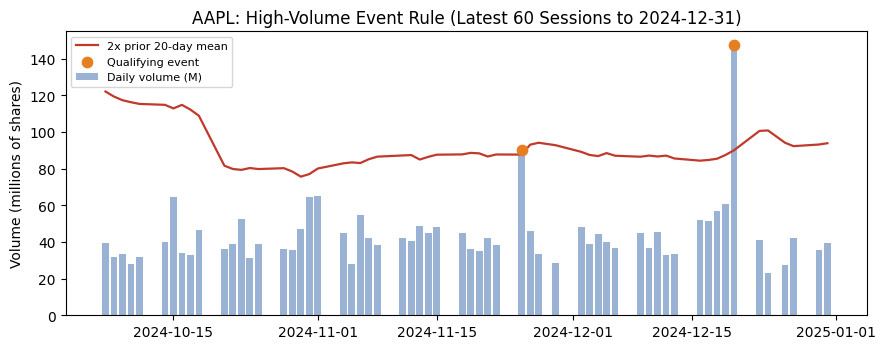


Saved outputs/feature_table.csv | Common valid shares: 486
       Mean_Weekly_Return  Weekly_Beta   Recency  Frequency  Monetary_USD_bn
count            486.0000     486.0000  486.0000   486.0000         486.0000
mean               0.0029       0.9737   20.4074     2.9897          39.4042
std                0.0027       0.4073   21.3424     1.3308         129.1388
min               -0.0045       0.0555    4.0000     0.0000           1.2975
25%                0.0012       0.6666   11.0000     2.0000          10.1952
50%                0.0026       0.9506   11.0000     3.0000          16.6838
75%                0.0042       1.1795   14.7500     4.0000          32.2769
max                0.0178       3.7786  222.0000     8.0000        1847.6974


In [35]:
obs_date = close_v.index.max()
window_dates = close_v.index[-WINDOW:]
assert len(window_dates) == WINDOW
assert window_dates[-1] == obs_date

def _recency_days(event_dates, obs):
    return np.nan if len(event_dates) == 0 else int((obs - max(event_dates)).days)

assert _recency_days([pd.Timestamp("2024-09-15")], pd.Timestamp("2024-09-20")) == 5
assert _recency_days([pd.Timestamp("2024-09-20")], pd.Timestamp("2024-09-20")) == 0
assert np.isnan(_recency_days([], pd.Timestamp("2024-09-20")))

_test_vol = pd.Series([1_000_000.0] * 20 + [2_500_000.0, 2_000_000.0, 1_800_000.0])
_test_base = _test_vol.shift(1).rolling(20, min_periods=20).mean()
_test_flag = (_test_vol > 2.0 * _test_base) & _test_base.notna()
assert bool(_test_flag.iloc[20]) is True    # 2.5M > 2.0M -> qualifies
assert bool(_test_flag.iloc[21]) is False   # 2.0M not strictly > 2.0M -> does not qualify
assert bool(_test_flag.iloc[22]) is False   # 1.8M < threshold -> does not qualify
assert 100.0 * 2_000_000.0 == 200_000_000.0
print("Unit tests passed (Recency=5/0/NaN, strict >2x threshold, Close*Volume=$200M).")

# --- Compute RFM for all retained shares ---
rolling_20 = vol_v.shift(1).rolling(BASELINE, min_periods=BASELINE).mean()
high_vol_flags = (vol_v > MULT * rolling_20) & rolling_20.notna()

# Verify every day in the 60-session window has a complete 20-session baseline
assert rolling_20.loc[window_dates].notna().all().all()

rfm_rows = []
for t in valid_tickers:
    ev_dates = high_vol_flags.index[high_vol_flags[t]]
    R = _recency_days(ev_dates, obs_date)
    last_ev = str(ev_dates.max().date()) if len(ev_dates) else None
    F = int(high_vol_flags.loc[window_dates, t].sum())
    M = float((close_v.loc[window_dates, t] * vol_v.loc[window_dates, t]).sum())
    rfm_rows.append({
        "Ticker": t,
        "Observation_Date": str(obs_date.date()),
        "Last_Event_Date": last_ev,
        "Recency": R,
        "Frequency": F,
        "Monetary": M,
        "Monetary_USD_bn": M / 1e9,
        "Window_Start": str(window_dates[0].date()),
        "Window_End": str(window_dates[-1].date()),
        "Window_Sessions": len(window_dates),
    })

df_rfm = pd.DataFrame(rfm_rows).set_index("Ticker")

# Cross-checks on RFM consistency
no_event_tickers = df_rfm[df_rfm["Recency"].isna()].index.tolist()
for t in no_event_tickers:
    log_event(t, "1.4 RFM", "no_high_vol_event", "No qualifying high-volume day in valid history; excluded from RFM clustering")

window_cal_days = (obs_date - window_dates[0]).days
bad_rf = df_rfm[(df_rfm["Frequency"] > 0) & (df_rfm["Recency"] > window_cal_days)]
assert len(bad_rf) == 0, "Inconsistency: F > 0 but R exceeds window calendar length!"

print(f"Observation date : {obs_date.date()} | 60-session window: {window_dates[0].date()} to {window_dates[-1].date()}")
print(f"Shares with no qualifying event (R=NaN): {len(no_event_tickers)}")
print(f"Shares with F=0 in latest 60 sessions  : {int((df_rfm['Frequency'] == 0).sum())}")
print(f"Shares with R=0 (event on obs date)    : {int((df_rfm['Recency'] == 0).sum())}")

# --- Worked example: AAPL ---
EX = "AAPL"
ex_daily = pd.DataFrame({
    "Close": close_v[EX],
    "Volume": vol_v[EX],
    "Prev20_Mean_Vol": rolling_20[EX],
    "Threshold_2x": MULT * rolling_20[EX],
    "High_Volume": high_vol_flags[EX],
    "Traded_Value_USD": close_v[EX] * vol_v[EX],
})
ex_win = ex_daily.loc[window_dates]
ex_events = ex_win[ex_win["High_Volume"]]

print(f"\n=== Worked Example: {EX} (Observation date: {obs_date.date()}) ===")
print(f"Qualifying high-volume days in latest 60 sessions ({len(ex_events)}):")
print(ex_events[["Close", "Volume", "Prev20_Mean_Vol", "Threshold_2x", "Traded_Value_USD"]].to_string())
print(f"R = ({obs_date.date()} - {df_rfm.loc[EX, 'Last_Event_Date']}) = {int(df_rfm.loc[EX, 'Recency'])} calendar days")
print(f"F = {int(df_rfm.loc[EX, 'Frequency'])} qualifying days in latest 60 sessions")
print(f"M = ${df_rfm.loc[EX, 'Monetary']:,.2f} (${df_rfm.loc[EX, 'Monetary_USD_bn']:.2f} billion)")

# Plot worked example
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(ex_win.index, ex_win["Volume"] / 1e6, color="#9ab3d5", label="Daily volume (M)")
ax.plot(ex_win.index, ex_win["Threshold_2x"] / 1e6, color="#c0392b", lw=1.6, label="2x prior 20-day mean")
ax.scatter(ex_events.index, ex_events["Volume"] / 1e6, color="#e67e22", s=55, zorder=5, label="Qualifying event")
ax.set_title(f"{EX}: High-Volume Event Rule (Latest 60 Sessions to {obs_date.date()})")
ax.set_ylabel("Volume (millions of shares)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "worked_example_AAPL.png", dpi=150)
plt.show()

# Build common feature table (inner join on valid Risk/Return + valid RFM)
feature_table = df_risk.join(df_rfm, how="inner")
feature_table = feature_table[feature_table["Recency"].notna()].copy()
feature_table.insert(0, "Security", security_map.reindex(feature_table.index))
feature_table.insert(1, "GICS_Sector", sector_map.reindex(feature_table.index))
feature_table["Date_Added"] = date_added_map.reindex(feature_table.index)
feature_table.to_csv(OUT / "feature_table.csv")

print(f"\nSaved outputs/feature_table.csv | Common valid shares: {len(feature_table)}")
print(feature_table[["Mean_Weekly_Return", "Weekly_Beta", "Recency", "Frequency", "Monetary_USD_bn"]].describe().round(4))


## Task 2 Stock Segmentation and Sensitivity Analysis

### 2.1 Feature preparation

In [36]:
feat = feature_table.copy()
feat["Log1p_Monetary"] = np.log1p(feat["Monetary"])

cols_check = ["Mean_Weekly_Return", "Weekly_Beta", "Recency", "Frequency", "Monetary", "Log1p_Monetary"]
diag_rows = []
for c in cols_check:
    s = feat[c]
    z = (s - s.mean()) / s.std(ddof=0)
    diag_rows.append({
        "Feature": c,
        "Mean": s.mean(),
        "Median": s.median(),
        "SD": s.std(ddof=1),
        "Skew": s.skew(),
        "Outliers_|z|>3": int((z.abs() > 3).sum()),
    })
diag_df = pd.DataFrame(diag_rows)
diag_df.to_csv(OUT / "skew_outlier_diagnostics.csv", index=False)
print("Skew & outlier diagnostics:")
print(diag_df.round(4).to_string(index=False))

scaler_risk = StandardScaler()
scaler_rfm = StandardScaler()
X_risk = scaler_risk.fit_transform(feat[["Mean_Weekly_Return", "Weekly_Beta"]])
X_rfm = scaler_rfm.fit_transform(feat[["Recency", "Frequency", "Log1p_Monetary"]])

assert X_risk.shape == (len(feat), 2) and X_rfm.shape == (len(feat), 3)
print(f"\nStandardised matrices ready: X_risk={X_risk.shape}, X_rfm={X_rfm.shape}")


Skew & outlier diagnostics:
           Feature         Mean       Median           SD    Skew  Outliers_|z|>3
Mean_Weekly_Return 2.900000e-03 2.600000e-03 2.700000e-03  0.8675               6
       Weekly_Beta 9.737000e-01 9.506000e-01 4.073000e-01  1.1036               2
           Recency 2.040740e+01 1.100000e+01 2.134240e+01  3.6458              11
         Frequency 2.989700e+00 3.000000e+00 1.330800e+00  0.4247               5
          Monetary 3.940419e+10 1.668382e+10 1.291388e+11 11.6838               5
    Log1p_Monetary 2.368210e+01 2.353770e+01 9.422000e-01  1.0791               7

Standardised matrices ready: X_risk=(486, 2), X_rfm=(486, 3)


### 2.2 & 2.3 - Agglomerative clustering & K means clustering

=== Risk/Return k=2..8 ===
     Matrix  k  Ward_Sil  Ward_Min                       Ward_Sizes  KM_Sil  KM_Inertia  KM_Min                         KM_Sizes
Risk_Return  2    0.3395        92                        [92, 394]  0.3870       621.6     143                       [143, 343]
Risk_Return  3    0.2738        92                   [92, 164, 230]  0.3289       461.2     119                  [119, 165, 202]
Risk_Return  4    0.2821        48               [48, 92, 164, 182]  0.3270       371.6      40              [40, 132, 154, 160]
Risk_Return  5    0.3041        48            [48, 66, 92, 98, 182]  0.3406       309.6      27          [27, 50, 112, 131, 166]
Risk_Return  6    0.3204         5         [5, 48, 66, 87, 98, 182]  0.3349       265.1       5       [5, 43, 50, 105, 127, 156]
Risk_Return  7    0.3240         5     [5, 22, 48, 66, 87, 98, 160]  0.3285       227.2       5    [5, 41, 47, 77, 85, 103, 128]
Risk_Return  8    0.3208         5 [5, 22, 31, 48, 56, 66, 98, 160]  0

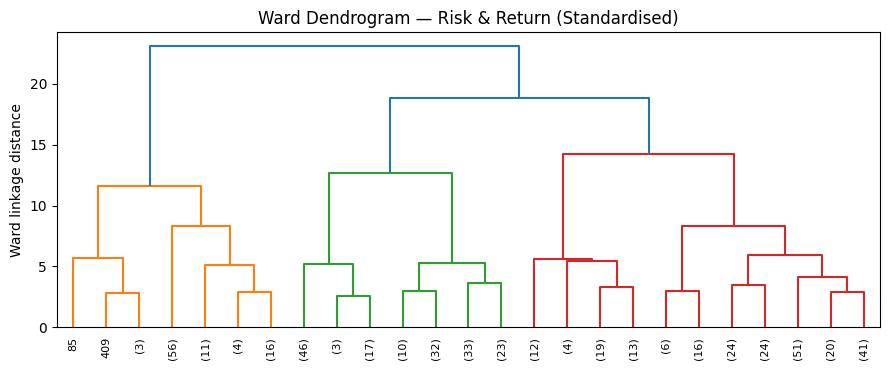

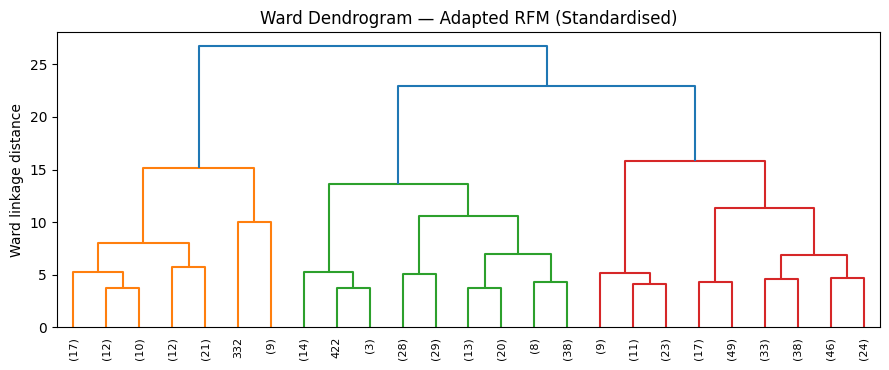

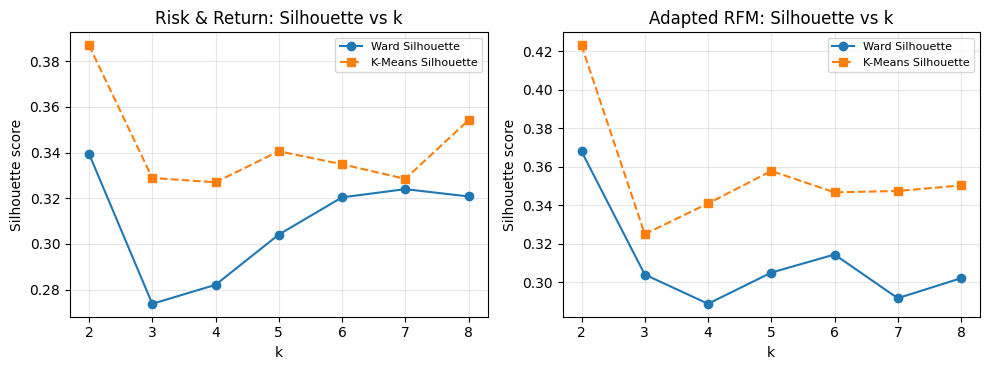


K-Means seed stability (ARI vs seed 42, seeds 0..9):
  Risk/Return (k=3): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
  RFM         (k=3): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [37]:
def eval_k_range(X, name):
    rows = []
    Z = linkage(X, method="ward", metric="euclidean")
    for k in K_RANGE:
        w_lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        w_sizes = pd.Series(w_lab).value_counts().sort_values().tolist()
        w_sil = silhouette_score(X, w_lab)

        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
        km_lab = km.labels_
        km_sizes = pd.Series(km_lab).value_counts().sort_values().tolist()
        km_sil = silhouette_score(X, km_lab)

        rows.append({
            "Matrix": name, "k": k,
            "Ward_Sil": round(w_sil, 4), "Ward_Min": w_sizes[0], "Ward_Sizes": str(w_sizes),
            "KM_Sil": round(km_sil, 4), "KM_Inertia": round(km.inertia_, 1),
            "KM_Min": km_sizes[0], "KM_Sizes": str(km_sizes),
        })
    return pd.DataFrame(rows), Z

diag_risk, Z_risk = eval_k_range(X_risk, "Risk_Return")
diag_rfm, Z_rfm = eval_k_range(X_rfm, "RFM")
k_diag = pd.concat([diag_risk, diag_rfm], ignore_index=True)
k_diag.to_csv(OUT / "k_diagnostics.csv", index=False)

print("=== Risk/Return k=2..8 ===")
print(diag_risk.to_string(index=False))
print("\n=== RFM k=2..8 ===")
print(diag_rfm.to_string(index=False))

# Plot dendrograms
for Z, title, fname in [
    (Z_risk, "Ward Dendrogram — Risk & Return (Standardised)", "dendrogram_risk_return.png"),
    (Z_rfm, "Ward Dendrogram — Adapted RFM (Standardised)", "dendrogram_rfm.png"),
]:
    fig, ax = plt.subplots(figsize=(9, 3.8))
    dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=90, leaf_font_size=8, ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.savefig(FIG / fname, dpi=150)
    plt.show()

# Plot silhouette & elbow diagnostics
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, df_d, title in [(axes[0], diag_risk, "Risk & Return"), (axes[1], diag_rfm, "Adapted RFM")]:
    ax.plot(df_d["k"], df_d["Ward_Sil"], "o-", label="Ward Silhouette")
    ax.plot(df_d["k"], df_d["KM_Sil"], "s--", label="K-Means Silhouette")
    ax.set_title(f"{title}: Silhouette vs k")
    ax.set_xlabel("k"); ax.set_ylabel("Silhouette score"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "k_silhouette_diagnostics.png", dpi=150)
plt.show()

# Select k (balanced silhouette, cluster sizes, and interpretability)
K_RISK = 3
K_RFM = 3

# Fit final four baseline models
feat["Risk_Ward"] = AgglomerativeClustering(n_clusters=K_RISK, linkage="ward").fit_predict(X_risk) + 1
km_risk = KMeans(n_clusters=K_RISK, n_init=50, random_state=SEED).fit(X_risk)
feat["Risk_KMeans"] = km_risk.labels_ + 1

feat["RFM_Ward"] = AgglomerativeClustering(n_clusters=K_RFM, linkage="ward").fit_predict(X_rfm) + 1
km_rfm = KMeans(n_clusters=K_RFM, n_init=50, random_state=SEED).fit(X_rfm)
feat["RFM_KMeans"] = km_rfm.labels_ + 1

# K-Means multi-seed stability check
stab_risk = [round(adjusted_rand_score(km_risk.labels_, KMeans(n_clusters=K_RISK, n_init=50, random_state=s).fit_predict(X_risk)), 4) for s in range(10)]
stab_rfm = [round(adjusted_rand_score(km_rfm.labels_, KMeans(n_clusters=K_RFM, n_init=50, random_state=s).fit_predict(X_rfm)), 4) for s in range(10)]
print(f"\nK-Means seed stability (ARI vs seed 42, seeds 0..9):")
print(f"  Risk/Return (k={K_RISK}): {stab_risk}")
print(f"  RFM         (k={K_RFM}): {stab_rfm}")


### 2.4 Cluster profiles and algorithm comparison


=== Profile: Risk_Ward ===
             N  Share_%  Ret_Mean_%  Ret_Med_%  Beta_Mean  Beta_Med  R_Mean  R_Med  F_Mean  F_Med  M_Mean_Bn  M_Med_Bn
Risk_Ward                                                                                                             
1          230     47.3       0.146      0.171      1.110     1.038    18.9   11.0    3.06    3.0      33.80     14.11
2           92     18.9       0.632      0.550      1.298     1.218    23.7   11.0    3.20    3.0      78.78     24.18
3          164     33.7       0.287      0.327      0.601     0.578    20.6   11.0    2.78    3.0      25.17     17.65

=== Profile: Risk_KMeans ===
               N  Share_%  Ret_Mean_%  Ret_Med_%  Beta_Mean  Beta_Med  R_Mean  R_Med  F_Mean  F_Med  M_Mean_Bn  M_Med_Bn
Risk_KMeans                                                                                                             
1            202     41.6       0.259      0.259      0.631     0.622    19.9   11.0    2.91    3.0      

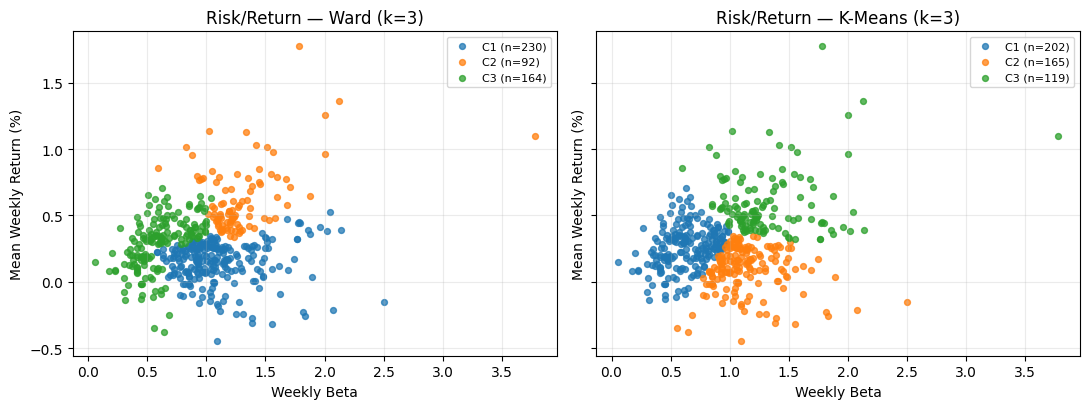

RFM PCA explained variance: PC1=0.458, PC2=0.336, Total=0.794


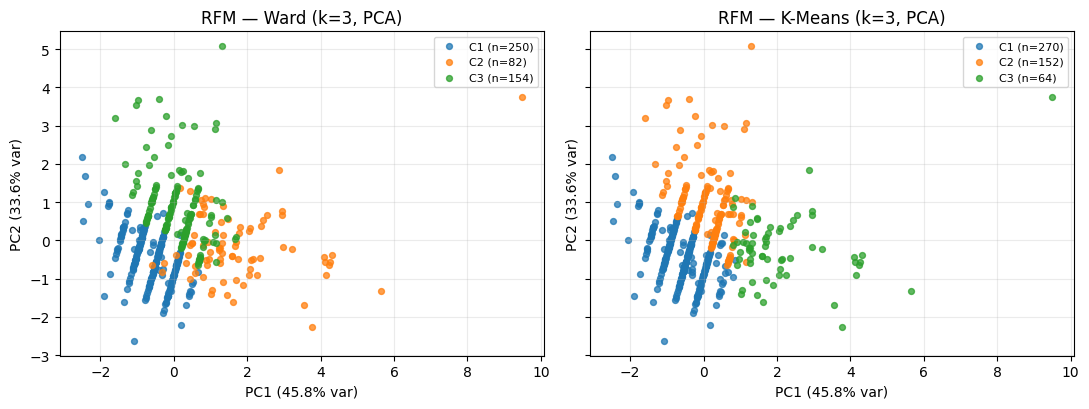

In [38]:
def profile_table(df, col):
    g = df.groupby(col)
    out = pd.DataFrame({
        "N": g.size(),
        "Share_%": (g.size() / len(df) * 100).round(1),
        "Ret_Mean_%": (g["Mean_Weekly_Return"].mean() * 100).round(3),
        "Ret_Med_%": (g["Mean_Weekly_Return"].median() * 100).round(3),
        "Beta_Mean": g["Weekly_Beta"].mean().round(3),
        "Beta_Med": g["Weekly_Beta"].median().round(3),
        "R_Mean": g["Recency"].mean().round(1),
        "R_Med": g["Recency"].median().round(1),
        "F_Mean": g["Frequency"].mean().round(2),
        "F_Med": g["Frequency"].median().round(1),
        "M_Mean_Bn": g["Monetary_USD_bn"].mean().round(2),
        "M_Med_Bn": g["Monetary_USD_bn"].median().round(2),
    })
    return out

for col in ["Risk_Ward", "Risk_KMeans", "RFM_Ward", "RFM_KMeans"]:
    p = profile_table(feat, col)
    p.to_csv(OUT / f"profile_{col}.csv")
    print(f"\n=== Profile: {col} ===")
    print(p.to_string())

ari_risk_wk = adjusted_rand_score(feat["Risk_Ward"], feat["Risk_KMeans"])
ari_rfm_wk = adjusted_rand_score(feat["RFM_Ward"], feat["RFM_KMeans"])
print(f"\nAlgorithm agreement (Ward vs K-Means on same {len(feat)} shares):")
print(f"  Risk/Return ARI = {ari_risk_wk:.4f}")
print(f"  RFM         ARI = {ari_rfm_wk:.4f}")

# 2D Risk/Return plots (original units)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, col, title in [(axes[0], "Risk_Ward", f"Risk/Return — Ward (k={K_RISK})"),
                       (axes[1], "Risk_KMeans", f"Risk/Return — K-Means (k={K_RISK})")]:
    for c in sorted(feat[col].unique()):
        sub = feat[feat[col] == c]
        ax.scatter(sub["Weekly_Beta"], sub["Mean_Weekly_Return"] * 100, s=18, alpha=0.75, label=f"C{c} (n={len(sub)})")
    ax.set_title(title); ax.set_xlabel("Weekly Beta"); ax.set_ylabel("Mean Weekly Return (%)")
    ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIG / "clusters_risk_return.png", dpi=150)
plt.show()

# 2D PCA projection of standardised RFM
pca = PCA(n_components=2, random_state=SEED)
X_rfm_pca = pca.fit_transform(X_rfm)
ev = pca.explained_variance_ratio_
print(f"RFM PCA explained variance: PC1={ev[0]:.3f}, PC2={ev[1]:.3f}, Total={ev.sum():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, col, title in [(axes[0], "RFM_Ward", f"RFM — Ward (k={K_RFM}, PCA)"),
                       (axes[1], "RFM_KMeans", f"RFM — K-Means (k={K_RFM}, PCA)")]:
    for c in sorted(feat[col].unique()):
        mask = feat[col] == c
        ax.scatter(X_rfm_pca[mask, 0], X_rfm_pca[mask, 1], s=18, alpha=0.75, label=f"C{c} (n={mask.sum()})")
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({ev[0]*100:.1f}% var)"); ax.set_ylabel(f"PC2 ({ev[1]*100:.1f}% var)")
    ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIG / "clusters_rfm_pca.png", dpi=150)
plt.show()


### 2.5 RFM sensitivity and correlated inputs

=== Correlations among R, F, log1p(M) ===
                Recency  Frequency  Log1p_Monetary
Recency          1.0000    -0.3463          0.1524
Frequency       -0.3463     1.0000          0.0128
Log1p_Monetary   0.1524     0.0128          1.0000

Monetary removal (Ward, fixed k=3):
  ARI (Full RFM vs R+F only)     : 0.2912
  eta^2 of log1p(M) — Full RFM   : 0.5162
  eta^2 of log1p(M) — R+F only   : 0.0041
  Robustness ARI (raw R vs logR) : 0.8820

Traded value (USD bn) by Full RFM Ward cluster:
          count  median   mean
RFM_Ward                      
1           250   11.18  11.76
2            82   17.85  47.16
3           154   39.70  80.15

Traded value (USD bn) by R+F-only Ward cluster:
              count  median   mean
RFM_Ward_NoM                      
1                89   20.85  46.53
2               272   14.86  39.40
3               125   17.70  34.34


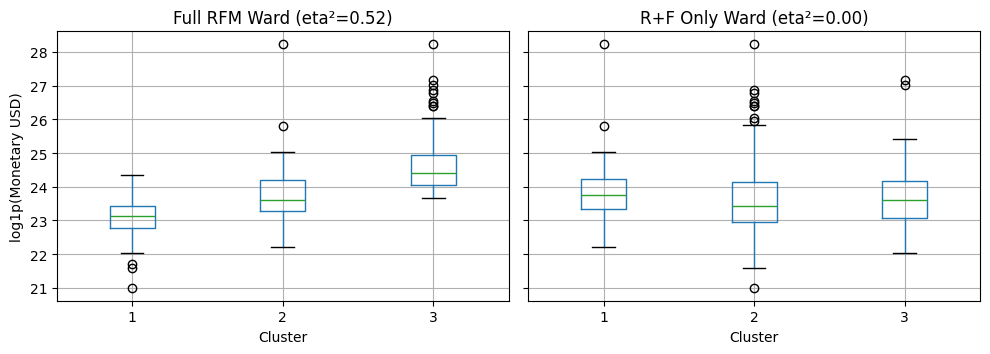

In [39]:
rfm_corr = feat[["Recency", "Frequency", "Log1p_Monetary"]].corr()
rfm_corr.to_csv(OUT / "rfm_correlations.csv")
print("=== Correlations among R, F, log1p(M) ===")
print(rfm_corr.round(4))

# Controlled Monetary-removal comparison (same shares, same Ward algorithm, same k, re-standardised afresh)
X_rf_only = StandardScaler().fit_transform(feat[["Recency", "Frequency"]])
feat["RFM_Ward_NoM"] = AgglomerativeClustering(n_clusters=K_RFM, linkage="ward").fit_predict(X_rf_only) + 1

ari_noM = adjusted_rand_score(feat["RFM_Ward"], feat["RFM_Ward_NoM"])

def eta_squared(values, labels):
    grand = values.mean()
    ss_tot = ((values - grand) ** 2).sum()
    ss_bet = sum(len(g) * (g.mean() - grand) ** 2 for _, g in values.groupby(labels))
    return float(ss_bet / ss_tot)

eta_full = eta_squared(feat["Log1p_Monetary"], feat["RFM_Ward"])
eta_noM = eta_squared(feat["Log1p_Monetary"], feat["RFM_Ward_NoM"])

# Robustness check: log1p(Recency) vs raw Recency
X_rfm_logR = StandardScaler().fit_transform(
    pd.DataFrame({"logR": np.log1p(feat["Recency"]), "F": feat["Frequency"], "logM": feat["Log1p_Monetary"]})
)
lab_logR = AgglomerativeClustering(n_clusters=K_RFM, linkage="ward").fit_predict(X_rfm_logR) + 1
ari_logR = adjusted_rand_score(feat["RFM_Ward"], lab_logR)

print(f"\nMonetary removal (Ward, fixed k={K_RFM}):")
print(f"  ARI (Full RFM vs R+F only)     : {ari_noM:.4f}")
print(f"  eta^2 of log1p(M) — Full RFM   : {eta_full:.4f}")
print(f"  eta^2 of log1p(M) — R+F only   : {eta_noM:.4f}")
print(f"  Robustness ARI (raw R vs logR) : {ari_logR:.4f}")

print("\nTraded value (USD bn) by Full RFM Ward cluster:")
print(feat.groupby("RFM_Ward")["Monetary_USD_bn"].agg(["count", "median", "mean"]).round(2))
print("\nTraded value (USD bn) by R+F-only Ward cluster:")
print(feat.groupby("RFM_Ward_NoM")["Monetary_USD_bn"].agg(["count", "median", "mean"]).round(2))

# Boxplot comparing Monetary separation
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
feat.boxplot(column="Log1p_Monetary", by="RFM_Ward", ax=axes[0])
axes[0].set_title(f"Full RFM Ward (eta²={eta_full:.2f})"); axes[0].set_xlabel("Cluster"); axes[0].set_ylabel("log1p(Monetary USD)")
feat.boxplot(column="Log1p_Monetary", by="RFM_Ward_NoM", ax=axes[1])
axes[1].set_title(f"R+F Only Ward (eta²={eta_noM:.2f})"); axes[1].set_xlabel("Cluster")
plt.suptitle("")
plt.tight_layout()
plt.savefig(FIG / "monetary_removal_comparison.png", dpi=150)
plt.show()


## Task 3 Business Intelligence and Critical Review

In [40]:
# 1. Risk/Return vs RFM agreement
ari_cross_ward = adjusted_rand_score(feat["Risk_Ward"], feat["RFM_Ward"])
ari_cross_km = adjusted_rand_score(feat["Risk_KMeans"], feat["RFM_KMeans"])
print(f"Cross-matrix agreement (Risk/Return vs RFM): Ward ARI = {ari_cross_ward:.4f} | K-Means ARI = {ari_cross_km:.4f}")

# 2. GICS Sector composition (% within each cluster)
sec_risk = pd.crosstab(feat["Risk_Ward"], feat["GICS_Sector"], normalize="index").mul(100).round(1)
sec_rfm = pd.crosstab(feat["RFM_Ward"], feat["GICS_Sector"], normalize="index").mul(100).round(1)
sec_risk.to_csv(OUT / "sector_composition_Risk_Ward.csv")
sec_rfm.to_csv(OUT / "sector_composition_RFM_Ward.csv")
print("\n=== Sector composition % (Risk_Ward) ===")
print(sec_risk.to_string())
print("\n=== Sector composition % (RFM_Ward) ===")
print(sec_rfm.to_string())

# 3. Pairwise weekly return correlation (diversification check)
ret_mat = weekly_ret[feat.index]
corr_mat = ret_mat.corr().values
iu = np.triu_indices(len(feat), k=1)
overall_pair_corr = float(corr_mat[iu].mean())

def within_across_corr(labels):
    lab = np.asarray(labels)
    same = lab[iu[0]] == lab[iu[1]]
    return float(corr_mat[iu][same].mean()), float(corr_mat[iu][~same].mean())

w_risk, a_risk = within_across_corr(feat["Risk_Ward"])
w_rfm, a_rfm = within_across_corr(feat["RFM_Ward"])
print(f"\nPairwise weekly-return correlation ({len(feat)} shares, {len(iu[0]):,} pairs):")
print(f"  Overall average              : {overall_pair_corr:.4f}")
print(f"  Risk_Ward — within / across  : {w_risk:.4f} / {a_risk:.4f}")
print(f"  RFM_Ward  — within / across  : {w_rfm:.4f} / {a_rfm:.4f}")

# 4. Survivorship bias check using Wikipedia Date added
added_dt = pd.to_datetime(feat["Date_Added"], errors="coerce")
feat["Added_Post_2021"] = added_dt >= pd.Timestamp("2021-01-01")
surv = feat.groupby("Added_Post_2021").agg(
    N=("Mean_Weekly_Return", "size"),
    Mean_Weekly_Ret_Pct=("Mean_Weekly_Return", lambda s: round(s.mean() * 100, 4)),
    Median_Weekly_Ret_Pct=("Mean_Weekly_Return", lambda s: round(s.median() * 100, 4)),
    Mean_Beta=("Weekly_Beta", lambda s: round(s.mean(), 3)),
)
print("\n=== Survivorship-bias evidence (constituents added on/after 2021-01-01 vs earlier) ===")
print(surv.to_string())
print("Note: companies REMOVED from the S&P 500 during 2021-2024 are absent from the current Wikipedia list.")

# Save final cluster assignments and summary JSON
feat.to_csv(OUT / "cluster_assignments.csv")
summary = {
    "retrieval_date": RETRIEVAL_DATE,
    "observation_date": str(obs_date.date()),
    "study_period": f"{START} to {END} (exclusive)",
    "requested_sp500_tickers": len(tickers),
    "benchmark": BENCH,
    "excluded_tickers": len(excl_only),
    "final_common_shares": len(feat),
    "trading_sessions": len(bench_dates),
    "paired_complete_weeks": len(common_weeks),
    "k_risk": K_RISK,
    "k_rfm": K_RFM,
    "ari_risk_ward_vs_kmeans": round(float(ari_risk_wk), 4),
    "ari_rfm_ward_vs_kmeans": round(float(ari_rfm_wk), 4),
    "ari_rfm_full_vs_noM": round(float(ari_noM), 4),
    "eta2_logM_full": round(float(eta_full), 4),
    "eta2_logM_noM": round(float(eta_noM), 4),
    "ari_rfm_rawR_vs_logR": round(float(ari_logR), 4),
    "ari_risk_vs_rfm_ward": round(float(ari_cross_ward), 4),
    "pca_rfm_explained_var": [round(float(ev[0]), 4), round(float(ev[1]), 4)],
    "overall_pairwise_weekly_corr": round(overall_pair_corr, 4),
    "risk_ward_within_across_corr": [round(w_risk, 4), round(a_risk, 4)],
    "rfm_ward_within_across_corr": [round(w_rfm, 4), round(a_rfm, 4)],
    "post_2021_additions_in_sample": int(feat["Added_Post_2021"].sum()),
}
(OUT / "summary_metrics.json").write_text(json.dumps(summary, indent=2))
print("\nSaved outputs/cluster_assignments.csv and outputs/summary_metrics.json")
print(json.dumps(summary, indent=2))


Cross-matrix agreement (Risk/Return vs RFM): Ward ARI = 0.0244 | K-Means ARI = 0.0206

=== Sector composition % (Risk_Ward) ===
GICS_Sector  Communication Services  Consumer Discretionary  Consumer Staples  Energy  Financials  Health Care  Industrials  Information Technology  Materials  Real Estate  Utilities
Risk_Ward                                                                                                                                                                             
1                               3.0                    11.7               2.2     0.0        13.5         12.6         19.1                    18.7        7.0         10.0        2.2
2                               5.4                    12.0               0.0     4.3        14.1          2.2         22.8                    31.5        3.3          3.3        1.1
3                               4.9                     5.5              16.5     9.8        18.3         16.5          7.9                 